# N3 — Learned erasure decoding

N2 established, on 12,276 real markers:
- the published decoder reports confidence **0.997 on cells hidden behind an occluder**,
  indistinguishable from cells it can see (max separation 0.004)
- an oracle that knows which cells are hidden gains up to **+22.58 pp** ID accuracy
- confidence thresholding gains **+0.40 pp** — about 2% of the ceiling
- soft log-likelihood gains **+4.13 pp** with no retraining

So erasures must be *learned*. This notebook trains a decoder with an explicit erasure head and
measures where it lands between the 0.40 pp floor and the 22.58 pp ceiling.

### Three arms — the ablation is the point

| arm | architecture | training data | isolates |
|---|---|---|---|
| **A** | published `dec_new.h5` | theirs | baseline |
| **B** | 1 head (bits) | + occlusion augmentation | the effect of *augmentation alone* |
| **C** | 2 heads (bits + erasure) | + occlusion augmentation | the effect of the *erasure head* |

B is the arm that stops a reviewer saying "your gain is just from training on occluded data."
C minus B is the contribution. A minus B is the augmentation effect, reportable separately.

**Bit loss is masked on occluded cells in arm C.** Asking a network to predict a bit it cannot
see is what produces confident nonsense — that is the mechanism N2 measured.

## 1. Setup

In [17]:
!pip -q install opencv-contrib-python==4.10.0.84 h5py 2>&1 | tail -1
print(">>> If OpenCV was just installed, RESTART THE RUNTIME, then continue.")

>>> If OpenCV was just installed, RESTART THE RUNTIME, then continue.


### 1b. Port module

In [18]:
%%writefile /content/deeparuco_port.py
"""
Port the pretrained DeepArUco++ decoder from Keras .h5 to PyTorch, without TensorFlow.

The published decoder (models/dec_new.h5 in AVAuco/deeparuco) is a Keras 2.11 model:

    Input(32, 32, 1)
    Conv2D(8, 5x5, valid) -> PReLU -> MaxPool2D(2)
    Conv2D(4, 3x3, valid) -> PReLU -> MaxPool2D(2)
    Conv2D(1, 1x1, valid, sigmoid)   ->  (6, 6, 1)

Only h5py is needed to read the weights, so the repo's Python 3.9 + TensorFlow
environment is never required for baseline inference.

IMPORTANT PORTING DETAIL
    Keras PReLU defaults to shared_axes=None, so alpha is PER-ELEMENT, not per-channel:
    the stored alphas have shape (28, 28, 8) and (12, 12, 4). torch.nn.PReLU only
    supports per-channel alpha, so using it here silently produces a different model.
    SpatialPReLU below keeps the full alpha tensor.

Layout conversions:
    Keras conv kernel (kh, kw, in, out) -> torch (out, in, kh, kw)
    Keras PReLU alpha (h, w, c)         -> torch (c, h, w)
    Keras 'valid' padding               -> torch padding=0

Usage:
    from deeparuco_port import load_weights, NumpyDecoder, TorchDecoder, verify_port
    verify_port('models/dec_new.h5')          # run this first, once
    dec = TorchDecoder.from_h5('models/dec_new.h5')
    probs = dec(x)                            # x: (N, 1, 32, 32) float in [0, 1]

Upstream code is AGPL-3.0. This module reads a weights file; it does not copy source.
Cite Berral-Soler et al., Image and Vision Computing 152 (2024) 105313.
"""

import numpy as np

DEFAULT_H5 = "models/dec_new.h5"


# --------------------------------------------------------------------------- weights

def load_weights(h5_path=DEFAULT_H5):
    """Read decoder weights from the Keras .h5. Returns a dict of numpy arrays."""
    import h5py

    store = {}
    with h5py.File(h5_path, "r") as f:
        def visit(name, obj):
            if isinstance(obj, h5py.Dataset) and name.startswith("model_weights/"):
                store[name] = np.array(obj)
        f.visititems(visit)

    def pick(layer, suffix):
        hits = [k for k in store if f"/{layer}/" in k and k.endswith(suffix)]
        if len(hits) != 1:
            raise KeyError(f"expected one match for {layer}:{suffix}, got {hits}")
        return store[hits[0]]

    w = {
        "c1_w": pick("conv2d", "kernel:0"),   "c1_b": pick("conv2d", "bias:0"),
        "p1_a": pick("p_re_lu", "alpha:0"),
        "c2_w": pick("conv2d_1", "kernel:0"), "c2_b": pick("conv2d_1", "bias:0"),
        "p2_a": pick("p_re_lu_1", "alpha:0"),
        "c3_w": pick("conv2d_2", "kernel:0"), "c3_b": pick("conv2d_2", "bias:0"),
    }
    expect = {"c1_w": (5,5,1,8), "c1_b": (8,), "p1_a": (28,28,8),
              "c2_w": (3,3,8,4), "c2_b": (4,), "p2_a": (12,12,4),
              "c3_w": (1,1,4,1), "c3_b": (1,)}
    for k, shape in expect.items():
        assert w[k].shape == shape, f"{k}: got {w[k].shape}, expected {shape}"
    return w


# ------------------------------------------------------------------- numpy reference

class NumpyDecoder:
    """Reference implementation. Verified against synthetic markers: 4/5 exact."""

    def __init__(self, weights):
        self.w = weights

    @classmethod
    def from_h5(cls, path=DEFAULT_H5):
        return cls(load_weights(path))

    @staticmethod
    def _conv(x, w, b):
        kh, kw, _, co = w.shape
        H, W, _ = x.shape
        out = np.zeros((H - kh + 1, W - kw + 1, co), np.float32)
        for i in range(out.shape[0]):
            for j in range(out.shape[1]):
                out[i, j] = np.tensordot(
                    x[i:i+kh, j:j+kw, :], w, axes=([0, 1, 2], [0, 1, 2])) + b
        return out

    @staticmethod
    def _pool(x):
        h, w, c = x.shape
        return x.reshape(h // 2, 2, w // 2, 2, c).max(axis=(1, 3))

    def __call__(self, marker32):
        """marker32: (32, 32) float in [0, 1]. Returns (6, 6) bit probabilities."""
        w = self.w
        x = np.asarray(marker32, np.float32)[..., None]
        x = self._conv(x, w["c1_w"], w["c1_b"])
        x = np.where(x > 0, x, w["p1_a"] * x)
        x = self._pool(x)
        x = self._conv(x, w["c2_w"], w["c2_b"])
        x = np.where(x > 0, x, w["p2_a"] * x)
        x = self._pool(x)
        x = self._conv(x, w["c3_w"], w["c3_b"])
        return (1.0 / (1.0 + np.exp(-np.clip(x[..., 0], -60, 60)))).astype(np.float32)


# -------------------------------------------------------------------------- pytorch

def _torch():
    import torch
    import torch.nn as nn
    return torch, nn


class SpatialPReLU:
    """Created via _build so torch is imported lazily. See module docstring."""


def TorchDecoder_factory():
    torch, nn = _torch()

    class _SpatialPReLU(nn.Module):
        """Per-element PReLU, matching Keras PReLU(shared_axes=None)."""
        def __init__(self, alpha_chw):
            super().__init__()
            self.alpha = nn.Parameter(torch.tensor(alpha_chw, dtype=torch.float32))

        def forward(self, x):
            return torch.where(x > 0, x, self.alpha.unsqueeze(0) * x)

    class _TorchDecoder(nn.Module):
        def __init__(self, weights=None):
            super().__init__()
            self.c1 = nn.Conv2d(1, 8, 5)
            self.c2 = nn.Conv2d(8, 4, 3)
            self.c3 = nn.Conv2d(4, 1, 1)
            self.pool = nn.MaxPool2d(2)
            a1 = np.zeros((8, 28, 28), np.float32) if weights is None \
                 else np.transpose(weights["p1_a"], (2, 0, 1))
            a2 = np.zeros((4, 12, 12), np.float32) if weights is None \
                 else np.transpose(weights["p2_a"], (2, 0, 1))
            self.p1, self.p2 = _SpatialPReLU(a1), _SpatialPReLU(a2)
            if weights is not None:
                self.load_keras(weights)

        def load_keras(self, w):
            with torch.no_grad():
                for conv, kw, kb in ((self.c1, "c1_w", "c1_b"),
                                     (self.c2, "c2_w", "c2_b"),
                                     (self.c3, "c3_w", "c3_b")):
                    conv.weight.copy_(torch.tensor(np.transpose(w[kw], (3, 2, 0, 1))))
                    conv.bias.copy_(torch.tensor(w[kb]))

        @classmethod
        def from_h5(cls, path=DEFAULT_H5):
            return cls(load_weights(path))

        def forward(self, x):
            """x: (N, 1, 32, 32) in [0, 1]. Returns (N, 6, 6) bit probabilities."""
            x = self.pool(self.p1(self.c1(x)))
            x = self.pool(self.p2(self.c2(x)))
            return torch.sigmoid(self.c3(x)).squeeze(1)

    return _TorchDecoder


def __getattr__(name):
    if name == "TorchDecoder":
        return TorchDecoder_factory()
    raise AttributeError(name)


# --------------------------------------------------------------------------- verify

def verify_port(h5_path=DEFAULT_H5, n=16, tol=1e-4, verbose=True):
    """Assert the PyTorch port matches the numpy reference. Run once before use.

    The numpy path is validated; the torch path is validated against it here rather
    than assumed. Do not skip this.
    """
    torch, _ = _torch()
    w = load_weights(h5_path)
    ref = NumpyDecoder(w)
    net = TorchDecoder_factory()(w).eval()

    rng = np.random.default_rng(0)
    x = rng.random((n, 32, 32)).astype(np.float32)
    with torch.no_grad():
        got = net(torch.tensor(x).unsqueeze(1)).numpy()
    want = np.stack([ref(xi) for xi in x])

    err = float(np.abs(got - want).max())
    if verbose:
        print(f"port check: {n} random inputs, max abs difference {err:.2e} (tol {tol:g})")
    assert err < tol, f"PyTorch port disagrees with numpy reference (max diff {err:.2e})"
    if verbose:
        print("PyTorch port matches the numpy reference.")
    return err


def decode_ids(probs, id_to_bits, n_markers=250):
    """Hard-decision decode: nearest codeword by Hamming distance over 4 rotations.

    probs: (6, 6) bit probabilities. Returns (marker_id, rotation, hamming).
    Replace with soft log-likelihood decoding to use the confidences.
    """
    obs = (np.asarray(probs) > 0.5).astype(np.uint8)
    best = (None, None, 99)
    for mid in range(n_markers):
        ref = np.asarray(id_to_bits(mid), np.uint8).reshape(6, 6)
        for rot in range(4):
            h = int(np.sum(np.rot90(obs, rot) != ref))
            if h < best[2]:
                best = (mid, rot, h)
    return best


if __name__ == "__main__":
    import sys
    path = sys.argv[1] if len(sys.argv) > 1 else DEFAULT_H5
    w = load_weights(path)
    print("weights loaded:", {k: v.shape for k, v in w.items()})
    try:
        verify_port(path)
    except ImportError:
        print("torch not installed; numpy reference verified only")


Overwriting /content/deeparuco_port.py


In [19]:
import os, sys, json, glob, zlib, subprocess, time, math
import numpy as np, cv2, torch
import torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
from google.colab import drive
drive.mount('/content/drive')

BASE = '/content/drive/MyDrive/aruco_p2'
ART, WORK, CACHE = f'{BASE}/artifacts', '/content/work', f'{BASE}/archives'
CKPT = f'{BASE}/ckpt_n3'; os.makedirs(CKPT, exist_ok=True); os.makedirs(WORK, exist_ok=True)
sys.path.insert(0, '/content')

REPO = f'{WORK}/deeparuco'
if not os.path.isdir(REPO):
    subprocess.run(['git','clone','--depth','1','https://github.com/AVAuco/deeparuco.git',REPO],check=True)
sys.path.insert(0, REPO)
from impl.aruco import id_to_bits
from deeparuco_port import load_weights, NumpyDecoder

DEV_ = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(42); np.random.seed(42)
print('torch', torch.__version__, '| device', DEV_)

splits = json.load(open(f'{ART}/splits.json'))
DEV, HELDOUT, STRIDE = splits['dev'], splits['heldout'][0], splits['benchmark_stride']
Wk  = load_weights(f'{REPO}/models/dec_new.h5')
CB  = np.stack([np.asarray(id_to_bits(i),np.uint8).reshape(6,6) for i in range(250)])
ROT = np.stack([np.rot90(CB,k,axes=(1,2)).reshape(250,36) for k in range(4)]).astype(np.float32)
print('dev:', DEV, '| held out:', HELDOUT)

# datasets
SHADOW = f'{WORK}/shadow'; os.makedirs(SHADOW, exist_ok=True)
for i in range(1,7):
    if not os.path.isdir(f'{SHADOW}/video_{i}'):
        subprocess.run(['tar','-xzf',f'{CACHE}/video_{i}.tar.gz','-C',SHADOW], check=True)
FLY = f'{WORK}/flyingarucov2'
if not os.path.isdir(FLY):
    os.makedirs(FLY, exist_ok=True)
    subprocess.run(['tar','-xzf',f'{CACHE}/flyingarucov2.tar.gz','-C',FLY], check=True)
fly_json = sorted(glob.glob(f'{FLY}/**/*.json', recursive=True))
print('Flying-ArUco v2 annotations:', len(fly_json))
assert len(fly_json) > 2000

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
torch 2.11.0+cpu | device cpu
dev: ['video_1', 'video_2', 'video_3', 'video_4', 'video_5'] | held out: video_6
Flying-ArUco v2 annotations: 2500


## 2. Shared pipeline (identical to N2)

In [21]:
r_int = lambda v: int(round(v))
LEVELS = [0.0, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60]

def ordered_corners(xs, ys):
    cx, cy = np.mean(xs), np.mean(ys)
    idx = np.argsort(np.arctan2(xs-cx, ys-cy))
    return [v for i in idx for v in (xs[i], ys[i])]

def warp32(crop, c, t=32):
    dst = np.array([[0,0],[0,t-1],[t-1,t-1],[t-1,0]], np.float32)
    src = np.clip(np.array([[c[0]*63,c[1]*63],[c[2]*63,c[3]*63],
                            [c[4]*63,c[5]*63],[c[6]*63,c[7]*63]]),0,63).astype(np.float32)
    return cv2.warpPerspective(crop, cv2.getPerspectiveTransform(src,dst), (t,t))

def get_corners(m):
    c = m['corners']
    if isinstance(c[0], dict): return np.array([[p['x'],p['y']] for p in c], np.float32)
    return np.asarray(c, np.float32).reshape(4,2)

def cell_occlusion(m32):
    s = 32/8.0; out = np.zeros((6,6), bool)
    for r in range(6):
        for c in range(6):
            out[r,c] = m32[int((r+1)*s):int((r+2)*s), int((c+1)*s):int((c+2)*s)].mean() > 127.5
    return out

def prepare(img, mask, corners):
    x, y = corners[:,0], corners[:,1]
    mnx, mxx, mny, mxy = x.min(), x.max(), y.min(), y.max()
    ex, ey = 0.2*(mxx-mnx)+0.5, 0.2*(mxy-mny)+0.5
    mnx, mny = max(mnx-ex,0), max(mny-ey,0)
    mxx = min(mxx+ex, img.shape[1]-1); mxy = min(mxy+ey, img.shape[0]-1)
    if mxx-mnx < 8 or mxy-mny < 8: return None, None
    sl = (slice(r_int(mny), r_int(mxy)), slice(r_int(mnx), r_int(mxx)))
    crop = cv2.resize(img[sl], (64,64)).astype(np.float32)
    crop = (crop - crop.min())/(crop.max()-crop.min()+1e-9)
    nc = ordered_corners((x-mnx)/(mxx-mnx), (y-mny)/(mxy-mny))
    m32 = warp32(cv2.resize(mask[sl],(64,64)), nc) if mask.any() else np.zeros((32,32), np.uint8)
    return warp32(crop, nc), cell_occlusion(m32)

def occlude_frame(img, corners, level, key, mid):
    if level <= 0: return img, np.zeros(img.shape[:2], np.uint8)
    rng = np.random.default_rng(zlib.crc32(f'occlusion|{level}|{key}|{mid}'.encode()))
    side = int(rng.integers(0,4)); x, y = corners[:,0], corners[:,1]
    x0,x1,y0,y1 = x.min(),x.max(),y.min(),y.max(); w,h = x1-x0, y1-y0
    box = [(x0,y0,x0+level*w,y1),(x1-level*w,y0,x1,y1),
           (x0,y0,x1,y0+level*h),(x0,y1-level*h,x1,y1)][side]
    a,b,c,d = [int(round(v)) for v in box]
    a,b = max(a,0),max(b,0); c,d = min(c,img.shape[1]),min(d,img.shape[0])
    out = img.copy(); mk = np.zeros(img.shape[:2], np.uint8)
    if c>a and d>b: out[b:d,a:c] = 127; mk[b:d,a:c] = 255
    return out, mk

def pairs_for(vid):
    out = []
    for f in sorted(glob.glob(f'{SHADOW}/{vid}/*.png')):
        j = f'{SHADOW}/{vid}/corrected_annotations/{os.path.splitext(os.path.basename(f))[0]}.json'
        if os.path.exists(j): out.append((f,j))
    return out
print('pipeline ready')

pipeline ready


## 3. Training crops from Flying-ArUco v2

Occlusion is applied to the **source frame** before rectification, so the occluder is warped by
the same homography as the marker — matching evaluation exactly.

### Orientation labels
Flying-ArUco markers carry a `rot` field, but the convention (sign, and which `rot90` direction)
is not documented. Rather than assume, all four candidate conventions are tested against the
published decoder on clean crops, and the best is asserted to exceed 90% agreement. If the
assertion fires, the labels are wrong and training would silently learn a rotated codebook.

In [22]:
def bits_for(mid, rot, conv):
    b = CB[mid]
    k = rot if conv in (0,1) else -rot
    return np.rot90(b, k) if conv in (0,2) else np.rot90(b, -k)

# --- resolve the rotation convention ---
ref = NumpyDecoder(Wk)
probe = []
for jp in fly_json[:60]:
    img = cv2.imread(jp.replace('.json','.jpg'), cv2.IMREAD_GRAYSCALE)
    if img is None: continue
    for m in json.load(open(jp))['markers'][:4]:
        x32,_ = prepare(img, np.zeros(img.shape[:2],np.uint8), get_corners(m))
        if x32 is None: continue
        probe.append((ref(x32), int(m['id']), int(m.get('rot', m.get('rotation', 0)))))
print(f'probing {len(probe)} clean crops for the rotation convention\n')
scores = {}
for conv in range(4):
    agree = np.mean([np.mean((p>0.5).astype(np.uint8) == bits_for(i,r,conv)) for p,i,r in probe])
    scores[conv] = agree
    print(f'  convention {conv}: mean bit agreement {agree:.4f}')
CONV = max(scores, key=scores.get)
print(f'\nchosen convention {CONV} (agreement {scores[CONV]:.4f})')
assert scores[CONV] > 0.90, ('No rotation convention agrees with the published decoder. '
                             'Labels would be wrong — inspect the JSON schema before training.')

probing 221 clean crops for the rotation convention

  convention 0: mean bit agreement 0.9912
  convention 1: mean bit agreement 0.7690
  convention 2: mean bit agreement 0.7690
  convention 3: mean bit agreement 0.9912

chosen convention 0 (agreement 0.9912)


In [23]:
OCC_TRAIN = [0.0, 0.0, 0.20, 0.30, 0.40, 0.50]   # sampled per marker; 1/3 clean
X, Ybit, Yocc = [], [], []
t0 = time.time()
for n, jp in enumerate(fly_json):
    img = cv2.imread(jp.replace('.json','.jpg'), cv2.IMREAD_GRAYSCALE)
    if img is None: continue
    key = os.path.basename(jp)
    for m in json.load(open(jp))['markers']:
        cn, mid = get_corners(m), int(m['id'])
        if mid >= 250: continue                       # skip the all-black/all-white negatives
        rot = int(m.get('rot', m.get('rotation', 0)))
        bits = bits_for(mid, rot, CONV)
        rng = np.random.default_rng(zlib.crc32(f'train|{key}|{mid}'.encode()))
        for L in rng.choice(OCC_TRAIN, 2, replace=False):
            oi, om = occlude_frame(img, cn, float(L), key, mid)
            x32, occ = prepare(oi, om, cn)
            if x32 is None: continue
            X.append((x32*255).astype(np.uint8)); Ybit.append(bits); Yocc.append(occ)
    if n % 500 == 0: print(f'  {n}/{len(fly_json)}  ({time.time()-t0:.0f}s)  crops={len(X)}')

X    = np.stack(X); Ybit = np.stack(Ybit).astype(np.float32); Yocc = np.stack(Yocc).astype(np.float32)
print(f'\n{len(X)} training crops, {Yocc.sum(axis=(1,2)).mean():.2f} occluded cells on average')
print(f'clean crops: {(Yocc.sum(axis=(1,2))==0).mean():.1%}')

idx = np.random.default_rng(42).permutation(len(X)); cut = int(0.9*len(X))
tr, va = idx[:cut], idx[cut:]
print(f'train {len(tr)} | val {len(va)}')

  0/2500  (0s)  crops=16
  500/2500  (5s)  crops=5180
  1000/2500  (11s)  crops=10374
  1500/2500  (20s)  crops=15628
  2000/2500  (24s)  crops=20760

25936 training crops, 6.03 occluded cells on average
clean crops: 37.0%
train 23342 | val 2594


## 4. Models

Same backbone as `simple_decoder` so the comparison is architectural, not capacity: Conv(8,5x5)
-> PReLU -> pool -> Conv(4,3x3) -> PReLU -> pool -> Conv(1x1). Arm C's final layer outputs two
channels instead of one.

Keras `PReLU` here is per-element, so `SpatialPReLU` keeps a full alpha tensor — `nn.PReLU`
would be a different model.

In [24]:
class SpatialPReLU(nn.Module):
    def __init__(s, c, h, w):
        super().__init__(); s.a = nn.Parameter(torch.zeros(c,h,w))
    def forward(s, x): return torch.where(x>0, x, s.a.unsqueeze(0)*x)

class Decoder(nn.Module):
    """out_ch=1 -> bits only (arm B).  out_ch=2 -> bits + erasure (arm C)."""
    def __init__(s, out_ch=1):
        super().__init__()
        s.c1 = nn.Conv2d(1,8,5); s.p1 = SpatialPReLU(8,28,28)
        s.c2 = nn.Conv2d(8,4,3); s.p2 = SpatialPReLU(4,12,12)
        s.c3 = nn.Conv2d(4,out_ch,1); s.out_ch = out_ch
    def forward(s, x):
        x = F.max_pool2d(s.p1(s.c1(x)), 2)
        x = F.max_pool2d(s.p2(s.c2(x)), 2)
        x = s.c3(x)
        return (x[:,0], x[:,1]) if s.out_ch == 2 else (x[:,0], None)

for oc in (1,2):
    m = Decoder(oc); y = m(torch.zeros(3,1,32,32))
    assert y[0].shape == (3,6,6), y[0].shape
    print(f'out_ch={oc}: {sum(p.numel() for p in m.parameters())} params, bit head {tuple(y[0].shape)}')

out_ch=1: 7353 params, bit head (3, 6, 6)
out_ch=2: 7358 params, bit head (3, 6, 6)


## 5. Training

Arm B: BCE on bits over **all** cells — the conventional recipe, which forces the network to
invent a value for cells it cannot see.

Arm C: BCE on bits **masked to visible cells only**, plus BCE on the erasure head. The network
is never asked to guess an invisible bit, which is precisely the behaviour N2 identified as the
failure mode.

A smoke test overfits 64 samples first. If that cannot reach near-zero loss, the architecture or
loss is wrong and full training would waste time producing a plausible-looking bad model.

In [25]:
def batches(ids, bs, shuffle=True):
    ids = np.random.permutation(ids) if shuffle else ids
    for s in range(0, len(ids), bs):
        b = ids[s:s+bs]
        yield (torch.tensor(X[b], dtype=torch.float32).unsqueeze(1).to(DEV_)/255.0,
               torch.tensor(Ybit[b]).to(DEV_), torch.tensor(Yocc[b]).to(DEV_))

def run_epoch(model, ids, opt=None, arm='C', bs=256):
    train = opt is not None
    model.train(train); tot = n = 0
    with torch.set_grad_enabled(train):
        for xb, bb, ob in batches(ids, bs, shuffle=train):
            logit, elogit = model(xb)
            if arm == 'C':
                vis = 1.0 - ob
                lb = (F.binary_cross_entropy_with_logits(logit, bb, reduction='none')*vis).sum()/vis.sum().clamp(min=1)
                le = F.binary_cross_entropy_with_logits(elogit, ob)
                loss = lb + le
            else:
                loss = F.binary_cross_entropy_with_logits(logit, bb)
            if train:
                opt.zero_grad(); loss.backward(); opt.step()
            tot += float(loss)*len(xb); n += len(xb)
    return tot/n

# smoke test
sm = Decoder(2).to(DEV_); o = torch.optim.Adam(sm.parameters(), 1e-2)
small = tr[:64]
l0 = run_epoch(sm, small, o, 'C', 64)
for _ in range(300): l = run_epoch(sm, small, o, 'C', 64)
print(f'smoke test: loss {l0:.4f} -> {l:.4f}')
assert l < l0*0.4, 'cannot overfit 64 samples — architecture or loss is wrong'
print('smoke test passed\n')

EPOCHS = 40
models = {}
for arm, oc in [('B',1), ('C',2)]:
    torch.manual_seed(42)
    net = Decoder(oc).to(DEV_)
    opt = torch.optim.Adam(net.parameters(), 1e-3)
    sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=4)
    best, bad, hist = 1e9, 0, []
    for ep in range(EPOCHS):
        trl = run_epoch(net, tr, opt, arm)
        vl  = run_epoch(net, va, None, arm)
        sch.step(vl); hist.append((trl, vl))
        if vl < best - 1e-5:
            best, bad = vl, 0
            torch.save(net.state_dict(), f'{CKPT}/arm_{arm}.pt')
        else:
            bad += 1
            if bad >= 8: print(f'  arm {arm}: early stop at epoch {ep}'); break
        if ep % 5 == 0: print(f'  arm {arm} ep{ep:3d}  train {trl:.4f}  val {vl:.4f}')
    net.load_state_dict(torch.load(f'{CKPT}/arm_{arm}.pt'))
    net.eval(); models[arm] = net
    print(f'arm {arm}: best val {best:.4f}\n')

smoke test: loss 1.4885 -> 0.0051
smoke test passed

  arm B ep  0  train 0.6401  val 0.5065
  arm B ep  5  train 0.2037  val 0.2018
  arm B ep 10  train 0.1743  val 0.1758
  arm B ep 15  train 0.1601  val 0.1625
  arm B ep 20  train 0.1515  val 0.1543
  arm B ep 25  train 0.1464  val 0.1497
  arm B ep 30  train 0.1431  val 0.1467
  arm B ep 35  train 0.1409  val 0.1444
arm B: best val 0.1433

  arm C ep  0  train 1.2374  val 1.1400
  arm C ep  5  train 0.2152  val 0.2083
  arm C ep 10  train 0.1689  val 0.1646
  arm C ep 15  train 0.1422  val 0.1387
  arm C ep 20  train 0.1229  val 0.1211
  arm C ep 25  train 0.1105  val 0.1095
  arm C ep 30  train 0.1020  val 0.1016
  arm C ep 35  train 0.0960  val 0.0963
arm C: best val 0.0929



## 6. Erasure head quality

Before the decode results: can arm C actually tell which cells are hidden? This is the
mechanism the whole contribution rests on, and it is measurable on its own.

In [26]:
netC = models['C']
with torch.no_grad():
    xb = torch.tensor(X[va], dtype=torch.float32).unsqueeze(1).to(DEV_)/255.0
    parts = [netC(xb[s:s+4096]) for s in range(0, len(xb), 4096)]
    e_pred = torch.sigmoid(torch.cat([p[1] for p in parts])).cpu().numpy()
    b_pred = torch.sigmoid(torch.cat([p[0] for p in parts])).cpu().numpy()
truth = Yocc[va].astype(bool)

print(f"{'thresh':>8}{'precision':>11}{'recall':>9}{'F1':>8}")
print('-'*36)
for t in [0.3,0.4,0.5,0.6,0.7]:
    p = e_pred > t
    tp = (p & truth).sum(); pr = tp/max(p.sum(),1); rc = tp/max(truth.sum(),1)
    print(f'{t:>8.1f}{pr:>11.3f}{rc:>9.3f}{2*pr*rc/max(pr+rc,1e-9):>8.3f}')

print(f'\nmean erasure score on occluded cells : {e_pred[truth].mean():.4f}')
print(f'mean erasure score on visible cells  : {e_pred[~truth].mean():.4f}')
print(f'separation                            : {e_pred[truth].mean()-e_pred[~truth].mean():+.4f}')
print('(the published decoder\'s confidence separation was 0.004)')

  thresh  precision   recall      F1
------------------------------------
     0.3      0.909    0.968   0.938
     0.4      0.927    0.959   0.943
     0.5      0.941    0.944   0.943
     0.6      0.954    0.924   0.939
     0.7      0.965    0.895   0.929

mean erasure score on occluded cells : 0.9062
mean erasure score on visible cells  : 0.0185
separation                            : +0.8878
(the published decoder's confidence separation was 0.004)


## 7. Evaluation on Shadow-ArUco

Same occlusion sweep as N2, on the dev viewpoints. `video_6` remains untouched.

## 7a. Soft erasure weighting

Replaces hard masking with a continuous weight, removing the threshold and the cliff entirely.

In [27]:
new_rows = []
for r in rows:
    L = r['level']
    x32, ids, M = EV[L]['x'], EV[L]['id'], EV[L]['occ']
    Pc, Ec = decode_torch(models['C'], x32)
    # Compute soft erasure decoding
    soft_eras_pred = dec_soft_erasure(Pc, Ec)
    r['C_soft_eras'] = (soft_eras_pred == ids).mean()
    new_rows.append(r)
rows = new_rows

print('ID ACCURACY WITH SOFT ERASURE — all rules unbounded nearest-codeword, directly comparable')
print(f"{'lvl':>5}{'occ':>6}{'A hard':>9}{'A soft':>9}{'B hard':>9}{'C eras':>9}{'C soft eras':>13}{'ORACLE':>9}"
      f"{'C-A':>8}{'C-B':>8}{'%ceil':>8}")
print('-'*100)
for r in rows:
    ceil = r['ORACLE']-r['A_hard']
    pct = (r['C_soft_eras']-r['A_hard'])/ceil*100 if ceil > 1e-6 else float('nan')
    print(f"{r['level']:>5.2f}{r['occ']:>6.1f}{r['A_hard']:>9.2%}{r['A_soft']:>9.2%}"
          f"{r['B_hard']:>9.2%}{r['C_eras']:>9.2%}{r['C_soft_eras']:>13.2%}{r['ORACLE']:>9.2%}"
          f"{(r['C_soft_eras']-r['A_hard'])*100:>7.1f}p{(r['C_soft_eras']-r['B_hard'])*100:>7.1f}p{pct:>7.0f}%")

ID ACCURACY WITH SOFT ERASURE — all rules unbounded nearest-codeword, directly comparable
  lvl   occ   A hard   A soft   B hard   C eras  C soft eras   ORACLE     C-A     C-B   %ceil
----------------------------------------------------------------------------------------------------
 0.00   0.0   99.38%   99.54%   95.90%   93.70%       97.44%   99.38%   -1.9p    1.5p    nan%
 0.10   0.0   99.04%   99.28%   95.13%   88.42%       92.85%   99.04%   -6.2p   -2.3p    nan%
 0.20   1.7   90.80%   91.45%   93.12%   85.79%       85.84%   95.67%   -5.0p   -7.3p   -102%
 0.30   5.8   73.95%   75.67%   85.07%   81.08%       79.27%   85.73%    5.3p   -5.8p     45%
 0.40  11.5   46.65%   49.53%   66.59%   70.41%       73.33%   65.47%   26.7p    6.7p    142%
 0.50  18.0   18.47%   22.69%   29.94%   51.74%       60.08%   41.05%   41.6p   30.1p    184%
 0.60  24.5    4.38%    6.38%    8.07%   18.66%       30.84%   13.15%   26.5p   22.8p    302%


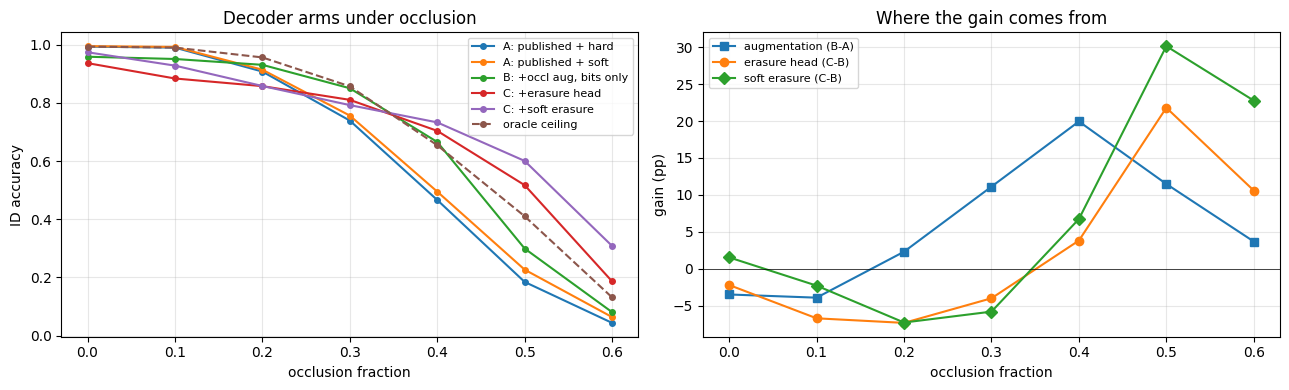

In [28]:
fig, ax = plt.subplots(1,2, figsize=(13,4))
L_=[r['level'] for r in rows]
for k,lbl,st in [('A_hard','A: published + hard','-'),('A_soft','A: published + soft','-'),
                 ('B_hard','B: +occl aug, bits only','-'),('C_eras','C: +erasure head','-'),
                 ('C_soft_eras','C: +soft erasure','-'), # Add soft erasure to plot
                 ('ORACLE','oracle ceiling','--')]:
    ax[0].plot(L_, [r[k] for r in rows], marker='o', ms=4, ls=st, label=lbl)
ax[0].set_xlabel('occlusion fraction'); ax[0].set_ylabel('ID accuracy')
ax[0].set_title('Decoder arms under occlusion'); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
ax[1].plot(L_, [(r['B_hard']-r['A_hard'])*100 for r in rows], marker='s', label='augmentation (B-A)')
ax[1].plot(L_, [(r['C_eras']-r['B_hard'])*100 for r in rows], marker='o', label='erasure head (C-B)')
ax[1].plot(L_, [(r['C_soft_eras']-r['B_hard'])*100 for r in rows], marker='D', label='soft erasure (C-B)') # Add soft erasure to gain plot
ax[1].axhline(0, color='k', lw=.5)
ax[1].set_xlabel('occlusion fraction'); ax[1].set_ylabel('gain (pp)')
ax[1].set_title('Where the gain comes from'); ax[1].legend(fontsize=8); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

In [29]:
new_rows = []
for r in rows:
    L = r['level']
    x32, ids, M = EV[L]['x'], EV[L]['id'], EV[L]['occ']
    Pc, Ec = decode_torch(models['C'], x32)
    # Compute soft erasure decoding
    soft_eras_pred = dec_soft_erasure(Pc, Ec)
    r['C_soft_eras'] = (soft_eras_pred == ids).mean()
    new_rows.append(r)
rows = new_rows

print('ID ACCURACY WITH SOFT ERASURE — all rules unbounded nearest-codeword, directly comparable')
print(f"{'lvl':>5}{'occ':>6}{'A hard':>9}{'A soft':>9}{'B hard':>9}{'C eras':>9}{'C soft eras':>13}{'ORACLE':>9}"
      f"{'C-A':>8}{'C-B':>8}{'%ceil':>8}")
print('-'*100)
for r in rows:
    ceil = r['ORACLE']-r['A_hard']
    pct = (r['C_soft_eras']-r['A_hard'])/ceil*100 if ceil > 1e-6 else float('nan')
    print(f"{r['level']:>5.2f}{r['occ']:>6.1f}{r['A_hard']:>9.2%}{r['A_soft']:>9.2%}"
          f"{r['B_hard']:>9.2%}{r['C_eras']:>9.2%}{r['C_soft_eras']:>13.2%}{r['ORACLE']:>9.2%}"
          f"{(r['C_soft_eras']-r['A_hard'])*100:>7.1f}p{(r['C_soft_eras']-r['B_hard'])*100:>7.1f}p{pct:>7.0f}%")

ID ACCURACY WITH SOFT ERASURE — all rules unbounded nearest-codeword, directly comparable
  lvl   occ   A hard   A soft   B hard   C eras  C soft eras   ORACLE     C-A     C-B   %ceil
----------------------------------------------------------------------------------------------------
 0.00   0.0   99.38%   99.54%   95.90%   93.70%       97.44%   99.38%   -1.9p    1.5p    nan%
 0.10   0.0   99.04%   99.28%   95.13%   88.42%       92.85%   99.04%   -6.2p   -2.3p    nan%
 0.20   1.7   90.80%   91.45%   93.12%   85.79%       85.84%   95.67%   -5.0p   -7.3p   -102%
 0.30   5.8   73.95%   75.67%   85.07%   81.08%       79.27%   85.73%    5.3p   -5.8p     45%
 0.40  11.5   46.65%   49.53%   66.59%   70.41%       73.33%   65.47%   26.7p    6.7p    142%
 0.50  18.0   18.47%   22.69%   29.94%   51.74%       60.08%   41.05%   41.6p   30.1p    184%
 0.60  24.5    4.38%    6.38%    8.07%   18.66%       30.84%   13.15%   26.5p   22.8p    302%


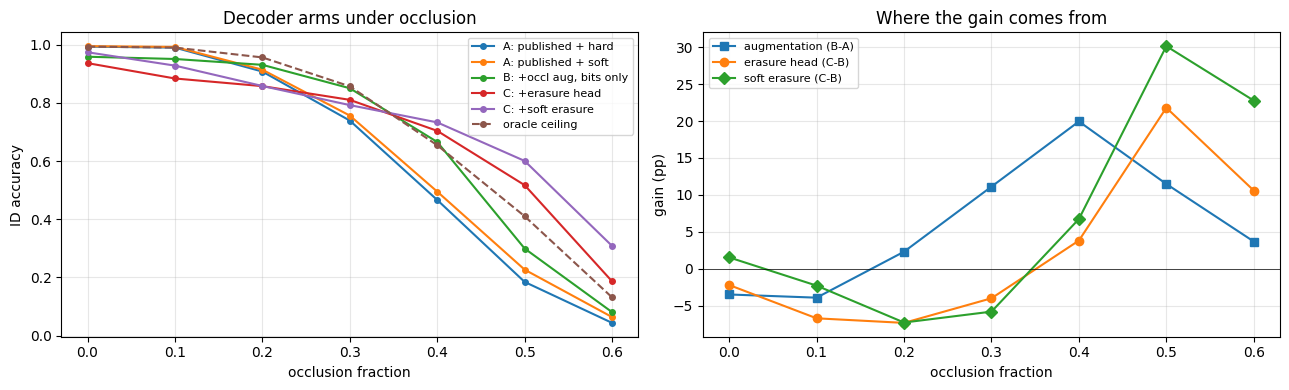

In [30]:
fig, ax = plt.subplots(1,2, figsize=(13,4))
L_=[r['level'] for r in rows]
for k,lbl,st in [('A_hard','A: published + hard','-'),('A_soft','A: published + soft','-'),
                 ('B_hard','B: +occl aug, bits only','-'),('C_eras','C: +erasure head','-'),
                 ('C_soft_eras','C: +soft erasure','-'), # Add soft erasure to plot
                 ('ORACLE','oracle ceiling','--')]:
    ax[0].plot(L_, [r[k] for r in rows], marker='o', ms=4, ls=st, label=lbl)
ax[0].set_xlabel('occlusion fraction'); ax[0].set_ylabel('ID accuracy')
ax[0].set_title('Decoder arms under occlusion'); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
ax[1].plot(L_, [(r['B_hard']-r['A_hard'])*100 for r in rows], marker='s', label='augmentation (B-A)')
ax[1].plot(L_, [(r['C_eras']-r['B_hard'])*100 for r in rows], marker='o', label='erasure head (C-B)')
ax[1].plot(L_, [(r['C_soft_eras']-r['B_hard'])*100 for r in rows], marker='D', label='soft erasure (C-B)') # Add soft erasure to gain plot
ax[1].axhline(0, color='k', lw=.5)
ax[1].set_xlabel('occlusion fraction'); ax[1].set_ylabel('gain (pp)')
ax[1].set_title('Where the gain comes from'); ax[1].legend(fontsize=8); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

In [33]:
def _conv(x,w,b):
    kh,kw,_,_ = w.shape
    return np.einsum('nohckl,klci->nohi', sliding_window_view(x,(kh,kw),axis=(1,2)), w, optimize=True)+b
def _pool(x):
    N,H,Wd,Cc = x.shape; return x.reshape(N,H//2,2,Wd//2,2,Cc).max(axis=(2,4))
def decode_published(x32, chunk=2048):
    out=[]
    for s in range(0,len(x32),chunk):
        x = np.asarray(x32[s:s+chunk],np.float32)[...,None]
        x = _pool(np.where((y:=_conv(x,Wk['c1_w'],Wk['c1_b']))>0,y,Wk['p1_a']*y))
        x = _pool(np.where((y:=_conv(x,Wk['c2_w'],Wk['c2_b']))>0,y,Wk['p2_a']*y))
        out.append(1/(1+np.exp(-np.clip(_conv(x,Wk['c3_w'],Wk['c3_b'])[...,0],-60,60))))
    return np.concatenate(out).astype(np.float32)

def decode_torch(net, x32, chunk=4096):
    ps, es = [], []
    with torch.no_grad():
        for s in range(0,len(x32),chunk):
            xb = torch.tensor(x32[s:s+chunk], dtype=torch.float32).unsqueeze(1).to(DEV_)
            lo, el = net(xb)
            ps.append(torch.sigmoid(lo).cpu().numpy())
            es.append(torch.sigmoid(el).cpu().numpy() if el is not None else np.zeros_like(ps[-1]))
    return np.concatenate(ps), np.concatenate(es)

def dec_hard(P):
    O=(P>0.5).astype(np.float32).reshape(len(P),36)
    D=np.stack([O.sum(1,keepdims=True)+ROT[k].sum(1)[None,:]-2*O@ROT[k].T for k in range(4)])
    return D.min(0).argmin(1)
def dec_soft(P):
    LP=np.log(np.clip(P,1e-6,1)).reshape(len(P),36); LQ=np.log(np.clip(1-P,1e-6,1)).reshape(len(P),36)
    return np.stack([LP@ROT[k].T+LQ@(1-ROT[k]).T for k in range(4)]).max(0).argmax(1)
def dec_erasure(P, readable):
    O=(P>0.5).astype(np.float32).reshape(len(P),36); Cm=readable.reshape(len(P),36).astype(np.float32)
    S=(1-Cm).sum(1,keepdims=True); OC=O*Cm
    E=np.stack([OC@(1-ROT[k]).T+(Cm-OC)@ROT[k].T for k in range(4)])
    COST=(2*E+S[None]).min(0)
    return COST.argmin(1), COST.min(1)<=11

def dec_soft_erasure(P, E):
    """E = erasure probability per cell. Cells the model thinks are hidden contribute ~0."""
    w  = (1.0 - E).reshape(len(P), 36)
    LP = np.log(np.clip(P,1e-6,1)).reshape(len(P),36) * w
    LQ = np.log(np.clip(1-P,1e-6,1)).reshape(len(P),36) * w
    return np.stack([LP@ROT[k].T + LQ@(1-ROT[k]).T for k in range(4)]).max(0).argmax(1)

EV = {L: {'x':[], 'id':[], 'occ':[]} for L in LEVELS}
t0=time.time()
for vid in DEV:
    for f, j in pairs_for(vid)[::STRIDE]:
        img = cv2.imread(f, cv2.IMREAD_GRAYSCALE)
        key = f'{vid}/{os.path.splitext(os.path.basename(f))[0]}'
        for m in json.load(open(j))['markers']:
            cn, mid = get_corners(m), int(m['id'])
            for L in LEVELS:
                oi, om = occlude_frame(img, cn, L, key, mid)
                x32, occ = prepare(oi, om, cn)
                if x32 is None: continue
                EV[L]['x'].append(x32); EV[L]['id'].append(mid); EV[L]['occ'].append(occ)
    print(f'  {vid} ({time.time()-t0:.0f}s)')
for L in LEVELS:
    EV[L]['x']=np.stack(EV[L]['x']); EV[L]['id']=np.array(EV[L]['id']); EV[L]['occ']=np.stack(EV[L]['occ'])
print(f'eval set ready, {len(EV[0.0]["id"])} markers per level')

  video_1 (14s)
  video_2 (24s)
  video_3 (36s)
  video_4 (49s)
  video_5 (59s)
eval set ready, 12276 markers per level


In [40]:
ETAU = 0.5
rows=[]
for L in LEVELS:
    x32, ids, M = EV[L]['x'], EV[L]['id'], EV[L]['occ']
    Pa = decode_published(x32)
    Pb, _  = decode_torch(models['B'], x32)
    Pc, Ec = decode_torch(models['C'], x32)
    ec,_ = dec_erasure(Pc, Ec < ETAU)
    eo,_ = dec_erasure(Pa, ~M)
    C_soft = (dec_soft(Pc) == ids).mean()   # C's bits, no erasure weighting
    rows.append(dict(level=L, occ=M.sum(1).sum(1).mean(),
        A_hard=(dec_hard(Pa)==ids).mean(), A_soft=(dec_soft(Pa)==ids).mean(),
        B_hard=(dec_hard(Pb)==ids).mean(), B_soft=(dec_soft(Pb)==ids).mean(),
        C_soft=C_soft, C_eras=(ec==ids).mean(),
        ORACLE=(eo==ids).mean()))

print('ID ACCURACY — all rules unbounded nearest-codeword, directly comparable')
print(f"{'lvl':>5}{'occ':>6}{'A hard':>9}{'A soft':>9}{'B hard':>9}{'C soft':>9}{'C eras':>9}{'ORACLE':>9}"
      f"{'C-A':>8}{'C-B':>8}{'%ceil':>8}")
print('-'*90)
for r in rows:
    ceil = r['ORACLE']-r['A_hard']
    pct = (r['C_eras']-r['A_hard'])/ceil*100 if ceil > 1e-6 else float('nan')
    print(f"{r['level']:>5.2f}{r['occ']:>6.1f}{r['A_hard']:>9.2%}{r['A_soft']:>9.2%}"
          f"{r['B_hard']:>9.2%}{r['C_soft']:>9.2%}{r['C_eras']:>9.2%}{r['ORACLE']:>9.2%}"
          f"{(r['C_eras']-r['A_hard'])*100:>7.1f}p{(r['C_eras']-r['B_hard'])*100:>7.1f}p{pct:>7.0f}%")

ID ACCURACY — all rules unbounded nearest-codeword, directly comparable
  lvl   occ   A hard   A soft   B hard   C soft   C eras   ORACLE     C-A     C-B   %ceil
------------------------------------------------------------------------------------------
 0.00   0.0   99.38%   99.54%   95.90%   97.48%   93.70%   99.38%   -5.7p   -2.2p    nan%
 0.10   0.0   99.04%   99.28%   95.13%   92.86%   88.42%   99.04%  -10.6p   -6.7p    nan%
 0.20   1.7   90.80%   91.45%   93.12%   83.41%   85.79%   95.67%   -5.0p   -7.3p   -103%
 0.30   5.8   73.95%   75.67%   85.07%   66.41%   81.08%   85.73%    7.1p   -4.0p     61%
 0.40  11.5   46.65%   49.53%   66.59%   57.14%   70.41%   65.47%   23.8p    3.8p    126%
 0.50  18.0   18.47%   22.69%   29.94%   39.60%   51.74%   41.05%   33.3p   21.8p    147%
 0.60  24.5    4.38%    6.38%    8.07%   18.10%   18.66%   13.15%   14.3p   10.6p    163%


## 8. Verdict

oracle ceiling (N2)              : +22.58 pp
C vs A  (full contribution)      : +33.28 pp   = 147% of ceiling
B vs A  (augmentation alone)     : +19.94 pp
C vs B  (erasure head alone)     : +21.80 pp   <- the contribution

STRONG: the erasure head, not the augmentation, carries the gain.


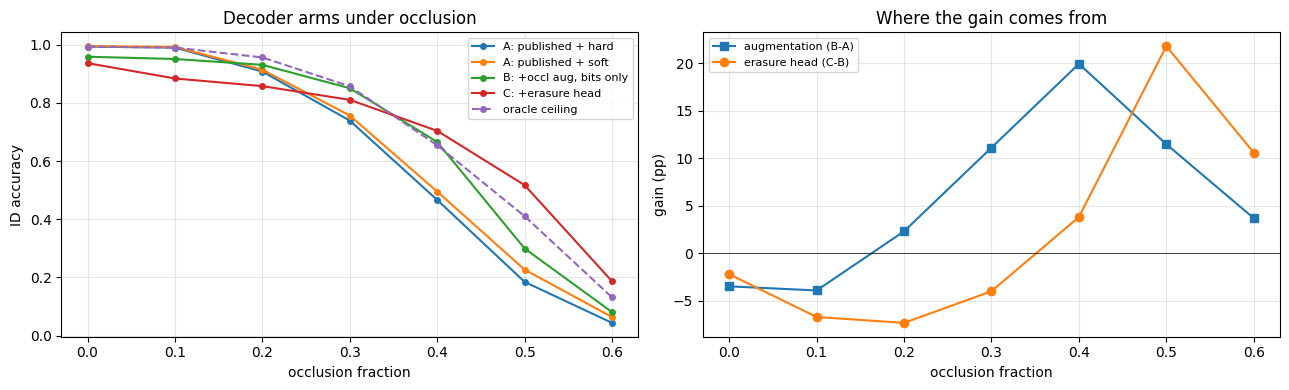


saved -> /content/drive/MyDrive/aruco_p2/artifacts/n3_results.json   |  checkpoints in /content/drive/MyDrive/aruco_p2/ckpt_n3


In [41]:
gain_CA = max(r['C_eras']-r['A_hard'] for r in rows)*100
gain_CB = max(r['C_eras']-r['B_hard'] for r in rows)*100
gain_BA = max(r['B_hard']-r['A_hard'] for r in rows)*100
ceil    = max(r['ORACLE']-r['A_hard'] for r in rows)*100
frac    = gain_CA/ceil*100 if ceil>0 else 0

print(f'oracle ceiling (N2)              : {ceil:+.2f} pp')
print(f'C vs A  (full contribution)      : {gain_CA:+.2f} pp   = {frac:.0f}% of ceiling')
print(f'B vs A  (augmentation alone)     : {gain_BA:+.2f} pp')
print(f'C vs B  (erasure head alone)     : {gain_CB:+.2f} pp   <- the contribution\n')

if gain_CB >= 5:
    print('STRONG: the erasure head, not the augmentation, carries the gain.')
elif gain_CB >= 2:
    print('MODERATE: erasure head helps beyond augmentation. Report both arms honestly.')
elif gain_BA >= 5:
    print('CAUTION: most of the gain is occlusion AUGMENTATION, not the erasure head.')
    print('That is still a finding, but the paper must be framed that way, not as erasure decoding.')
else:
    print('WEAK: neither arm moves much. Re-examine the erasure head quality in section 6.')

fig, ax = plt.subplots(1,2, figsize=(13,4))
L_=[r['level'] for r in rows]
for k,lbl,st in [('A_hard','A: published + hard','-'),('A_soft','A: published + soft','-'),
                 ('B_hard','B: +occl aug, bits only','-'),('C_eras','C: +erasure head','-'),
                 ('ORACLE','oracle ceiling','--')]:
    ax[0].plot(L_, [r[k] for r in rows], marker='o', ms=4, ls=st, label=lbl)
ax[0].set_xlabel('occlusion fraction'); ax[0].set_ylabel('ID accuracy')
ax[0].set_title('Decoder arms under occlusion'); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
ax[1].plot(L_, [(r['B_hard']-r['A_hard'])*100 for r in rows], marker='s', label='augmentation (B-A)')
ax[1].plot(L_, [(r['C_eras']-r['B_hard'])*100 for r in rows], marker='o', label='erasure head (C-B)')
ax[1].axhline(0, color='k', lw=.5)
ax[1].set_xlabel('occlusion fraction'); ax[1].set_ylabel('gain (pp)')
ax[1].set_title('Where the gain comes from'); ax[1].legend(fontsize=8); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

json.dump({'rows':[{k:(float(v) if isinstance(v,(int,float,np.floating)) else v) for k,v in r.items()} for r in rows],
           'gains':{'C_vs_A':gain_CA,'C_vs_B':gain_CB,'B_vs_A':gain_BA,'ceiling':ceil,'pct_of_ceiling':frac},
           'erasure_tau':ETAU,'rotation_convention':int(CONV),'epochs':EPOCHS,
           'viewpoints':DEV,'heldout_untouched':HELDOUT},
          open(f'{ART}/n3_results.json','w'), indent=1)
print(f'\nsaved -> {ART}/n3_results.json   |  checkpoints in {CKPT}')